#### Flaky Test Prediction: Models and Evaluation

KA1 Milestone 2 notebook. It runs the analysis planned in the research protocol on the FlakeFlagger data (Alshammari et al., 2021).

**Contents:** data preparation, fold design, baselines, four models on seen and unseen projects (RQ1), grouped permutation importance (RQ2), measurements versus test code words (RQ3), and a check on 25 different project groupings.

#### Setup

In [1]:
import ast
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import rankdata
from sklearn.model_selection import StratifiedGroupKFold, GroupKFold, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import average_precision_score
import sklearn

print("numpy", np.__version__, "| pandas", pd.__version__, "| scikit-learn", sklearn.__version__)

numpy 2.5.3 | pandas 3.0.5 | scikit-learn 1.9.0


#### Data preparation

In [2]:
BASE = "https://raw.githubusercontent.com/AlshammariA/FlakeFlagger/main/flakiness-predicter/result/"
df = pd.read_csv(BASE + "processed_data.csv")
vocab = pd.read_csv(BASE + "processed_data_with_vocabulary_per_test.csv", usecols=["test_name", "tokenList"])

smells = ["assertion-roulette", "conditional-test-logic", "eager-test", "fire-and-forget",
          "indirect-testing", "mystery-guest", "resource-optimism", "test-run-war"]
measures = ["testLength", "numAsserts", "numCoveredLines", "ExecutionTime",
            "projectSourceLinesCovered", "projectSourceClassesCovered",
            "hIndexModificationsPerCoveredLine_window100", "num_third_party_libs"]
for col in measures:
    df["rel_" + col] = df.groupby("project")[col].rank(pct=True)
features = smells + measures + ["rel_" + c for c in measures]

vocab["key"] = vocab["test_name"].str.lower()
df["key"] = df["test_name"].str.lower()
df = df.merge(vocab[["key", "tokenList"]].drop_duplicates("key"), on="key", how="left")
df["code_words"] = df["tokenList"].fillna("[]").apply(ast.literal_eval).str.join(" ")

X, y, texts = df[features], df["flaky"], df["code_words"]
print("Tests:", len(df), "| Flaky:", y.sum(), "| Features:", len(features))
print("Tests with missing measures:", X.isna().any(axis=1).sum())
print("Tests without code words:", df["tokenList"].isna().sum())

Tests: 22236 | Flaky: 811 | Features: 24
Tests with missing measures: 273
Tests without code words: 290


#### Projects with no flaky tests

In [3]:
by_project = df.groupby("project")["flaky"].agg(tests="size", flaky="sum")
print("No flaky tests:", list(by_project.index[by_project["flaky"] == 0]))
print("1 to 4 flaky tests:", list(by_project.index[by_project["flaky"].between(1, 4)]))

No flaky tests: ['jimfs']
1 to 4 flaky tests: ['achilles', 'assertj-core', 'commons-exec', 'elastic-job-lite', 'handlebars.java', 'ninja', 'zxing']


##### Interpretation

jimfs (212 tests) has no flaky tests, and seven projects have one to four. They stay in the data as examples of stable tests and as possible false alarms. PR-AUC is computed on each fold's held-out tests together, so it stays defined, and these projects still spend their 10% rerun budget.

#### Fold design

Each fold trains on part of the data and tests on the rest. Two setups are used:

- **Unseen projects:** the model is tested on projects it never saw in training, like using it on a brand-new project.
- **Seen projects:** the model is tested on new tests from projects it already trained on, like using it on new tests in a familiar project. Each test class stays together, so tests from one class are never split between training and testing.

In [4]:
projects = df["project"]
test_classes = df["project"] + "::" + df["testClassName"]
sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=0)
scenarios = {"Unseen projects": (list(sgkf.split(X, y, groups=projects)), projects),
             "Seen projects": (list(sgkf.split(X, y, groups=test_classes)), test_classes)}
unseen_folds = scenarios["Unseen projects"][0]

for name, (folds, groups) in scenarios.items():
    print(name)
    for k, (tr, te) in enumerate(folds, start=1):
        held = df.iloc[te]
        jimfs = " (includes jimfs)" if "jimfs" in set(held["project"]) and name == "Unseen projects" else ""
        print(f"  fold {k}: {held['project'].nunique():2d} projects, {len(te):5d} tests, {held['flaky'].sum():3d} flaky{jimfs}")

Unseen projects
  fold 1:  3 projects,  7258 tests, 217 flaky
  fold 2:  5 projects,  3830 tests, 128 flaky
  fold 3:  4 projects,  3927 tests, 194 flaky
  fold 4:  4 projects,  3324 tests, 167 flaky (includes jimfs)
  fold 5:  8 projects,  3897 tests, 105 flaky
Seen projects
  fold 1: 22 projects,  4445 tests, 162 flaky
  fold 2: 23 projects,  4446 tests, 162 flaky
  fold 3: 23 projects,  4446 tests, 162 flaky
  fold 4: 24 projects,  4451 tests, 163 flaky
  fold 5: 22 projects,  4448 tests, 162 flaky


#### How the scores are computed

- **PR-AUC:** computed on all held-out tests of a fold together.
- **Top 10% found:** each project reruns its own riskiest 10% of tests (rounded up). Flaky tests found are added up across the fold's projects and divided by all its flaky tests.
- **Tuning:** a grid search on the training fold only, with three inner folds grouped like the outer folds.

In [5]:
def top10_found(scores, te):
    held = df.iloc[te][["project", "flaky"]].assign(score=scores)
    found = sum(p.nlargest(int(np.ceil(0.10 * len(p))), "score")["flaky"].sum() for _, p in held.groupby("project"))
    return found / held["flaky"].sum()


def tuned_fit(pipe, grid, tr, groups, data=X):
    inner = StratifiedGroupKFold(n_splits=3, shuffle=True, random_state=0)
    search = GridSearchCV(pipe, grid, scoring="average_precision", cv=inner)
    return search.fit(data.iloc[tr], y.iloc[tr], groups=groups.iloc[tr])


def score_row(scenario, fold, model, score, te):
    return {"scenario": scenario, "fold": fold, "model": model, "flaky_rate": y.iloc[te].mean(),
            "pr_auc": average_precision_score(y.iloc[te], score), "top10_found": top10_found(score, te)}


def summarize(results):
    rule = results[results["model"] == "Slowest-first rule"][["scenario", "fold", "pr_auc"]]
    results = results.merge(rule, on=["scenario", "fold"], suffixes=("", "_rule"))
    results["beats_rule"] = results["pr_auc"] > results["pr_auc_rule"]
    return (results.groupby(["scenario", "model"], sort=False)
                   .agg(pr_auc=("pr_auc", "mean"), lowest=("pr_auc", "min"), highest=("pr_auc", "max"),
                        top10_found=("top10_found", "mean"), beats_rule=("beats_rule", "sum"))
                   .round(3))

#### Models

Random ranking and the slowest-first rule need no training, and logistic regression is the baseline model. A decision tree (depth 4, so its rules can be read), a random forest, and gradient boosting complete the comparison. Each model tunes one regularization setting and class weights (on or off).

In [6]:
weights = [None, "balanced"]
fill = ("fill", SimpleImputer(strategy="median"))
models = {
    "Logistic regression": (Pipeline([fill, ("scale", StandardScaler()), ("model", LogisticRegression(max_iter=3000))]),
                            {"model__C": [0.01, 0.1, 1], "model__class_weight": weights}),
    "Decision tree": (Pipeline([fill, ("model", DecisionTreeClassifier(max_depth=4, random_state=0))]),
                      {"model__min_samples_leaf": [5, 20, 50], "model__class_weight": weights}),
    "Random forest": (Pipeline([fill, ("model", RandomForestClassifier(n_estimators=200, random_state=0, n_jobs=-1))]),
                      {"model__min_samples_leaf": [1, 5, 20], "model__class_weight": weights}),
    "Gradient boosting": (Pipeline([fill, ("model", HistGradientBoostingClassifier(max_depth=3, random_state=0))]),
                          {"model__min_samples_leaf": [20, 50, 100], "model__class_weight": weights}),
}

#### RQ1: Seen and unseen projects

In [7]:
rows, scores, fitted = [], {}, {}
for scen, (folds, groups) in scenarios.items():
    for k, (tr, te) in enumerate(folds, start=1):
        s = {"Random ranking": np.random.RandomState(k).rand(len(te)),
             "Slowest-first rule": X["ExecutionTime"].iloc[te].values}
        for name, (pipe, grid) in models.items():
            fitted[(scen, k, name)] = tuned_fit(pipe, grid, tr, groups).best_estimator_
            s[name] = fitted[(scen, k, name)].predict_proba(X.iloc[te])[:, 1]
        for name, score in s.items():
            scores[(scen, k, name)] = score
            rows.append(score_row(scen, k, name, score, te))

rq1 = pd.DataFrame(rows)
rq1_summary = summarize(rq1)
rq1_summary

pr_auc  lowest  highest  top10_found  \
scenario        model                                                       
Unseen projects Random ranking        0.041   0.025    0.055        0.101   
                Slowest-first rule    0.168   0.064    0.310        0.272   
                Logistic regression   0.103   0.064    0.155        0.222   
                Decision tree         0.081   0.053    0.107        0.181   
                Random forest         0.171   0.043    0.430        0.252   
                Gradient boosting     0.101   0.054    0.163        0.266   
Seen projects   Random ranking        0.036   0.034    0.038        0.100   
                Slowest-first rule    0.154   0.152    0.159        0.249   
                Logistic regression   0.200   0.173    0.249        0.234   
                Decision tree         0.208   0.156    0.258        0.207   
                Random forest         0.518   0.396    0.597        0.303   
                Gradient boosting     0.488   0.349    0.559        0.301   

                                     beats_rule  
scenario        model                            
Unseen projects Random ranking                0  
                Slowest-first rule            0  
                Logistic regression           2  
                Decision tree                 0  
                Random forest                 3  
                Gradient boosting             2  
Seen projects   Random ranking                0  
                Slowest-first rule            0  
                Logistic regression           5  
                Decision tree                 5  
                Random forest                 5  
                Gradient boosting             5

In [8]:
order = ["Random ranking", "Slowest-first rule", *models]
unseen = rq1[rq1["scenario"] == "Unseen projects"]
unseen.pivot(index="fold", columns="model", values="pr_auc")[order].assign(
    flaky_rate=unseen.groupby("fold")["flaky_rate"].first()).round(3)

model,Random ranking,Slowest-first rule,Logistic regression,Decision tree,Random forest,Gradient boosting,flaky_rate
fold,,,,,,,
1,0.037,0.064,0.064,0.053,0.430,0.101,0.030
2,0.036,0.129,0.155,0.107,0.150,0.130,0.033
3,0.052,0.272,0.092,0.105,0.043,0.054,0.049
4,0.055,0.310,0.114,0.086,0.155,0.163,0.050
5,0.025,0.065,0.092,0.056,0.076,0.058,0.027


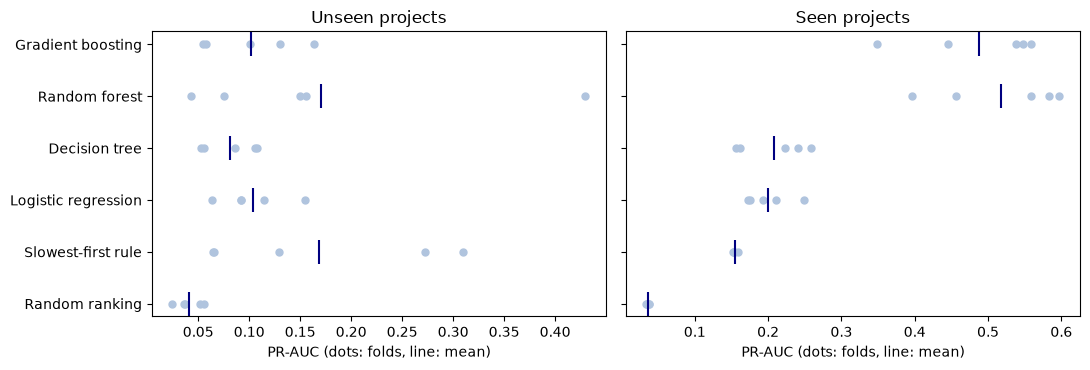

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
for ax, scen in zip(axes, scenarios):
    part = rq1[rq1["scenario"] == scen]
    for i, name in enumerate(order):
        vals = part.loc[part["model"] == name, "pr_auc"]
        ax.scatter(vals, [i] * len(vals), color="lightsteelblue", s=25)
        ax.scatter(vals.mean(), i, color="navy", marker="|", s=300)
    ax.set_yticks(range(len(order)), order)
    ax.set_title(scen)
    ax.set_xlabel("PR-AUC (dots: folds, line: mean)")
plt.tight_layout()
plt.show()

##### Interpretation

- **Seen projects:** every model beats the rule in all five folds, and the random forest scores more than three times the rule's PR-AUC (0.518 vs 0.154).
- **Unseen projects:** the random forest is only level with the rule (0.171 vs 0.168) and swings from 0.043 to 0.430 by fold; the other models fall below the rule.
- **10% rerun budget:** on new projects the rule finds 27% of flaky tests and the random forest 25%.

#### RQ2: What the model relies on

The best model on unseen projects is examined with permutation importance: a feature group is shuffled on the held-out projects, and the drop in PR-AUC shows how much the model relied on it. Features with a Spearman correlation of 0.6 or more are shuffled together, each with its project-relative version, so the model cannot lean on a partner. The eight rare test-smell flags form one group.

In [10]:
corr = df[measures].corr(method="spearman").round(2)
corr.index = corr.columns = ["length", "asserts", "covered", "time", "proj_lines", "proj_classes", "changes", "libs"]
raw_vs_rel = [df[c].corr(df["rel_" + c], method="spearman") for c in measures]
print(f"Each measure vs its project-relative version: {min(raw_vs_rel):.2f} to {max(raw_vs_rel):.2f}")
corr

Each measure vs its project-relative version: 0.61 to 0.86


,length,asserts,covered,time,proj_lines,proj_classes,changes,libs
length,1.00,0.63,0.55,0.22,0.36,0.14,-0.04,0.29
asserts,0.63,1.00,0.34,0.08,0.12,-0.06,-0.15,0.25
covered,0.55,0.34,1.00,0.29,0.74,0.55,0.03,0.42
time,0.22,0.08,0.29,1.00,0.45,0.43,0.06,0.19
proj_lines,0.36,0.12,0.74,0.45,1.00,0.89,0.12,0.26
proj_classes,0.14,-0.06,0.55,0.43,0.89,1.00,0.17,0.16
changes,-0.04,-0.15,0.03,0.06,0.12,0.17,1.00,0.03
libs,0.29,0.25,0.42,0.19,0.26,0.16,0.03,1.00


In [11]:
feature_groups = {
    "Run time": ["ExecutionTime"],
    "Code changes": ["hIndexModificationsPerCoveredLine_window100"],
    "Coverage": ["numCoveredLines", "projectSourceLinesCovered", "projectSourceClassesCovered"],
    "Test size": ["testLength", "numAsserts"],
    "Libraries": ["num_third_party_libs"],
}
feature_groups = {g: cols + ["rel_" + c for c in cols] for g, cols in feature_groups.items()}
feature_groups["Test smells"] = smells

best = rq1_summary.loc["Unseen projects"].loc[list(models), "pr_auc"].idxmax()
print("Best model on unseen projects:", best)

rng = np.random.RandomState(0)
imp = []
for k, (tr, te) in enumerate(unseen_folds, start=1):
    model, X_te, y_te = fitted[("Unseen projects", k, best)], X.iloc[te], y.iloc[te]
    base = average_precision_score(y_te, model.predict_proba(X_te)[:, 1])
    for group, cols in feature_groups.items():
        for repeat in range(5):
            X_shuffled = X_te.copy()
            X_shuffled[cols] = X_te[cols].values[rng.permutation(len(te))]
            drop = base - average_precision_score(y_te, model.predict_proba(X_shuffled)[:, 1])
            imp.append({"fold": k, "group": group, "drop": drop})

imp = pd.DataFrame(imp).groupby(["group", "fold"], as_index=False)["drop"].mean()
rq2 = (imp.groupby("group")["drop"]
          .agg(mean_drop="mean", lowest="min", highest="max", folds_above_zero=lambda d: (d > 0).sum())
          .sort_values("mean_drop", ascending=False).round(3))
rq2

Best model on unseen projects: Random forest


,mean_drop,lowest,highest,folds_above_zero
group,,,,
Code changes,0.071,-0.014,0.331,2
Coverage,0.060,-0.003,0.224,4
Run time,0.031,0.003,0.080,5
Test smells,0.009,-0.000,0.020,4
Test size,0.006,-0.017,0.037,2
Libraries,-0.007,-0.032,0.021,2


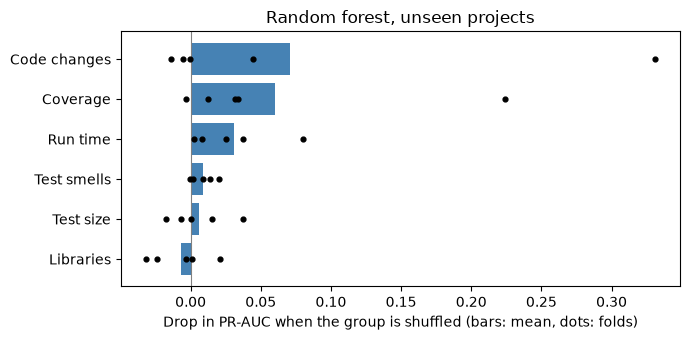

In [12]:
fig, ax = plt.subplots(figsize=(7, 3.5))
groups_sorted = rq2.index[::-1]
ax.barh(groups_sorted, rq2.loc[groups_sorted, "mean_drop"], color="steelblue")
for i, g in enumerate(groups_sorted):
    ax.scatter(imp.loc[imp["group"] == g, "drop"], [i] * 5, color="black", s=12, zorder=3)
ax.axvline(0, color="grey", linewidth=0.8)
ax.set_xlabel("Drop in PR-AUC when the group is shuffled (bars: mean, dots: folds)")
ax.set_title(f"{best}, unseen projects")
plt.tight_layout()
plt.show()

##### Interpretation

- Run time is the only group whose shuffling lowers PR-AUC in all five folds, though modestly (0.031 on average).
- Code changes and coverage have larger average drops (0.071 and 0.060), mostly from fold 1 (alluxio and okhttp), where the random forest scored 0.430.
- Libraries, test size, and test smells add little. This shows what the model used, not what makes a test flaky.

#### RQ3: Measurements, test code words, or both

- **Measurements only:** the best model from RQ1.
- **Code words only:** logistic regression on TF-IDF word weights, learned from the training fold only. Every word found in at least five training tests is kept; a fixed word cap would split ties between equally common words and change the results from one computer to another.
- **Both:** the two models' rankings are averaged.

Seen projects are included to check the combined model there too.

In [13]:
words_model = (Pipeline([("tfidf", TfidfVectorizer(min_df=5)),
                         ("model", LogisticRegression(max_iter=3000))]),
               {"model__C": [0.1, 1], "model__class_weight": weights})


def compare(measures_only, words_only, rule):
    return {"Slowest-first rule": rule, "Measurements only": measures_only, "Code words only": words_only,
            "Both (average rank)": (rankdata(measures_only) + rankdata(words_only)) / 2}


rows = []
for scen, (folds, groups) in scenarios.items():
    for k, (tr, te) in enumerate(folds, start=1):
        words_only = tuned_fit(*words_model, tr, groups, data=texts).predict_proba(texts.iloc[te])[:, 1]
        s = compare(scores[(scen, k, best)], words_only, scores[(scen, k, "Slowest-first rule")])
        for name, score in s.items():
            rows.append(score_row(scen, k, name, score, te))

rq3 = pd.DataFrame(rows)
summarize(rq3)

pr_auc  lowest  highest  top10_found  \
scenario        model                                                       
Unseen projects Slowest-first rule    0.168   0.064    0.310        0.272   
                Measurements only     0.171   0.043    0.430        0.252   
                Code words only       0.191   0.116    0.303        0.290   
                Both (average rank)   0.286   0.066    0.537        0.354   
Seen projects   Slowest-first rule    0.154   0.152    0.159        0.249   
                Measurements only     0.518   0.396    0.597        0.303   
                Code words only       0.529   0.371    0.659        0.346   
                Both (average rank)   0.595   0.475    0.673        0.361   

                                     beats_rule  
scenario        model                            
Unseen projects Slowest-first rule            0  
                Measurements only             3  
                Code words only               2  
                Both (average rank)           4  
Seen projects   Slowest-first rule            0  
                Measurements only             5  
                Code words only               5  
                Both (average rank)           5

##### Interpretation

- **Unseen projects:** code words alone beat the measurements (0.191 vs 0.171), and averaging the two rankings beats both: 0.286, ahead of the rule in four of five folds, with 35% of flaky tests found against 27% for the rule.
- The one loss is fold 3, where hbase holds 145 of the 194 flaky tests (0.066 vs 0.272 for the rule).
- **Seen projects:** the combined model is also best (0.595 vs 0.154), so it beats the rule in both settings.

#### Check on 25 project groupings

Scores on unseen projects depend on which projects land together in a fold, so the comparison is repeated with seeds 0 to 4. StratifiedGroupKFold gives the same folds for every seed (checked below), so the repeats use GroupKFold with shuffling, and each split's flaky count is kept.

In [14]:
seed0 = [sorted(set(projects.iloc[te])) for tr, te in unseen_folds]
seed1 = [sorted(set(projects.iloc[te])) for tr, te in
         StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=1).split(X, y, groups=projects)]
print("StratifiedGroupKFold gives the same folds for seeds 0 and 1:", seed0 == seed1)

StratifiedGroupKFold gives the same folds for seeds 0 and 1: True


In [15]:
pipe, grid = models[best]
rows = []
for seed in range(5):
    splits = GroupKFold(n_splits=5, shuffle=True, random_state=seed).split(X, y, groups=projects)
    for k, (tr, te) in enumerate(splits, start=1):
        measures_only = tuned_fit(pipe, grid, tr, projects).predict_proba(X.iloc[te])[:, 1]
        words_only = tuned_fit(*words_model, tr, projects, data=texts).predict_proba(texts.iloc[te])[:, 1]
        for name, score in compare(measures_only, words_only, X["ExecutionTime"].iloc[te].values).items():
            rows.append({**score_row("25 project groupings", f"{seed}-{k}", name, score, te), "flaky": y.iloc[te].sum()})

robust = pd.DataFrame(rows)
print("Flaky tests per split:", robust["flaky"].min(), "to", robust["flaky"].max())
robust_summary = summarize(robust)
robust_summary["median"] = robust.groupby("model", sort=False)["pr_auc"].median().round(3).values
robust_summary

Flaky tests per split: 13 to 398


pr_auc  lowest  highest  \
scenario             model                                          
25 project groupings Slowest-first rule    0.177   0.007    0.547   
                     Measurements only     0.150   0.025    0.373   
                     Code words only       0.180   0.048    0.466   
                     Both (average rank)   0.232   0.042    0.558   

                                          top10_found  beats_rule  median  
scenario             model                                                 
25 project groupings Slowest-first rule         0.272           0   0.114  
                     Measurements only          0.293          12   0.125  
                     Code words only            0.285          14   0.154  
                     Both (average rank)        0.365          18   0.224

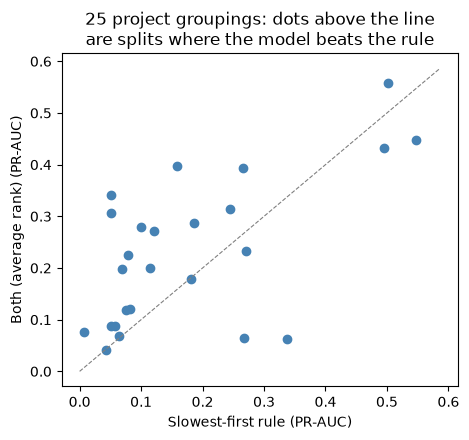

In [16]:
split = robust.pivot(index="fold", columns="model", values="pr_auc")
fig, ax = plt.subplots(figsize=(4.8, 4.5))
ax.scatter(split["Slowest-first rule"], split["Both (average rank)"], color="steelblue")
top = split[["Slowest-first rule", "Both (average rank)"]].max().max() * 1.05
ax.plot([0, top], [0, top], color="grey", linestyle="--", linewidth=0.8)
ax.set_xlabel("Slowest-first rule (PR-AUC)")
ax.set_ylabel("Both (average rank) (PR-AUC)")
ax.set_title("25 project groupings: dots above the line\nare splits where the model beats the rule")
plt.tight_layout()
plt.show()

##### Interpretation

- The combined model beats the rule in 18 of 25 splits (mean PR-AUC 0.232 vs 0.177, median 0.224 vs 0.114).
- The measurements alone win 12 splits and code words alone 14, so the gain comes from combining them.
- Scores still vary widely between splits (0.042 to 0.558 for the combined model).